### Agglomerative clustering (Flight prices)

In this example we aggregate (create summary variables that help clustering) the dataset in order to create a cluster with Agglomerative Clustering, that helps replacing the original flight code (over 1500 unique options).

In [26]:
import seaborn as sns
import pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.preprocessing import LabelEncoder

In [27]:
# load and test dataset
# the first column of the file is just an unnamed row number => use it as the index
df = pd.read_csv("flight_price_Clean_Dataset.csv", index_col=0)
df = df.dropna()


df

,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955
...,...,...,...,...,...,...,...,...,...,...,...
300148,Vistara,UK-822,Chennai,Morning,one,Evening,Hyderabad,Business,10.08,49,69265
300149,Vistara,UK-826,Chennai,Afternoon,one,Night,Hyderabad,Business,10.42,49,77105
300150,Vistara,UK-832,Chennai,Early_Morning,one,Night,Hyderabad,Business,13.83,49,79099
300151,Vistara,UK-828,Chennai,Early_Morning,one,Evening,Hyderabad,Business,10.00,49,81585


In [28]:
#check stops variable value counts
df['stops'].value_counts()

stops
one            250863
zero            36004
two_or_more     13286
Name: count, dtype: int64

In [29]:
#check class variable value counts
df['class'].value_counts()

class
Economy     206666
Business     93487
Name: count, dtype: int64

In [30]:
# handling variables
#stops
stops_mapper = {'zero': 0, 'one': 1, 'two_or_more': 2}
df['stops'] = df['stops'].map(stops_mapper)

# class
encoder = LabelEncoder()
df['class'] = encoder.fit_transform(df['class'])

In [31]:
# how many categories do we have?
print(f"Total categories: {df['flight'].nunique()}")

df['flight'].value_counts()

Total categories: 1561


flight
UK-706     3235
UK-772     2741
UK-720     2650
UK-836     2542
UK-822     2468
           ... 
6E-3211       1
6E-6474       1
6E-2914       1
SG-1058       1
6E-2939       1
Name: count, Length: 1561, dtype: int64

The big idea: generate new aggregate (summarizing) variables, THAT HELP the clustering algorithm to group different flights together.

NOTE: the price is our target variable, so it is NOT used in the aggregates. Otherwise the answer would leak into the clusters.

In [32]:
# you can even add more aggregations:
# Median
# Standard deviation
# Minimum and maximum
# Ticket count
# Possibly selected percentiles

# NOTE: the price is our target variable, so it is NOT used in the aggregates

flight_aggregates = df.groupby('flight').agg({
    'duration': 'mean',
    'stops': 'mean',
    'class': 'mean',
    'days_left': 'mean',
    'flight': 'count'
}).rename(columns={'flight': 'Ticket_Count'}).reset_index()

flight_aggregates

,flight,duration,stops,class,days_left,Ticket_Count
0,6E-102,3.208718,0.564103,1.000000,37.461538,39
1,6E-105,7.500000,1.000000,1.000000,47.000000,5
2,6E-113,5.660612,1.000000,1.000000,22.857143,49
3,6E-121,5.645000,0.750000,1.000000,47.000000,20
4,6E-123,6.750000,1.000000,1.000000,24.000000,5
...,...,...,...,...,...,...
1556,UK-988,16.382245,0.929037,0.466329,24.893555,1381
1557,UK-993,8.829067,0.901207,0.499451,26.805708,911
1558,UK-994,9.325067,0.928515,0.476826,25.538885,1273
1559,UK-995,10.471875,0.905273,0.501953,25.530273,1024


In [36]:
from sklearn.preprocessing import StandardScaler

# select the aggregate features we want to use
# and potentially scale
features = [
    'duration',
    'stops',
    'class',
    'days_left',
    'Ticket_Count'
]


# scaling is not strictly required by agglomerative clustering
# but it can be helpful => try with and without scaling
scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    flight_aggregates[features]
)

# X_scaled = flight_aggregates[features]

Let's use agglomerative clustering and combine flights into clusters (from over 1500 flight codes => 20 clusters!)

In [38]:
from sklearn.cluster import AgglomerativeClustering

clusterer = AgglomerativeClustering(
    n_clusters=20,
    linkage='ward'
)

flight_aggregates['Cluster'] = clusterer.fit_predict(X_scaled)

Let's study which flights were combined into which clusters!

In [39]:
# there are too many flights to print them all, so we print the size and a few examples
for cluster in sorted(flight_aggregates['Cluster'].unique()):
    flights = flight_aggregates.loc[
        flight_aggregates['Cluster'] == cluster,
        'flight'
    ].tolist()

    print(f"\nCluster {cluster}:")
    print(flights)


    # NOTE: similar flights tend to group together

    # this way the cluster seems like an ordinal category, but technically
    # it's still just a nominal category (you might need OneHotEncoding for the cluster!)


Cluster 0:
['6E-113', '6E-123', '6E-128', '6E-131', '6E-135', '6E-148', '6E-149', '6E-152', '6E-161', '6E-176', '6E-179', '6E-181', '6E-184', '6E-186', '6E-188', '6E-198', '6E-2001', '6E-2013', '6E-2031', '6E-2042', '6E-2043', '6E-205', '6E-207', '6E-2076', '6E-2083', '6E-2092', '6E-2097', '6E-2102', '6E-2107', '6E-213', '6E-2148', '6E-2154', '6E-2168', '6E-2178', '6E-2181', '6E-2193', '6E-221', '6E-2249', '6E-227', '6E-232', '6E-2329', '6E-2338', '6E-2343', '6E-2346', '6E-2367', '6E-2373', '6E-244', '6E-245', '6E-246', '6E-2479', '6E-251', '6E-255', '6E-261', '6E-2615', '6E-2616', '6E-2618', '6E-266', '6E-2685', '6E-2753', '6E-276', '6E-2769', '6E-282', '6E-2843', '6E-289', '6E-296', '6E-309', '6E-312', '6E-319', '6E-358', '6E-369', '6E-375', '6E-384', '6E-394', '6E-397', '6E-398', '6E-409', '6E-415', '6E-425', '6E-426', '6E-5018', '6E-502', '6E-5031', '6E-5059', '6E-5063', '6E-5073', '6E-512', '6E-515', '6E-519', '6E-5202', '6E-5206', '6E-5214', '6E-524', '6E-528', '6E-5302', '6E-53

Let's also create a dendrogram to study the hierarchies!

It's also possible to create "loose clusters" by cutting the dendrogram in higher levels / crossroads!

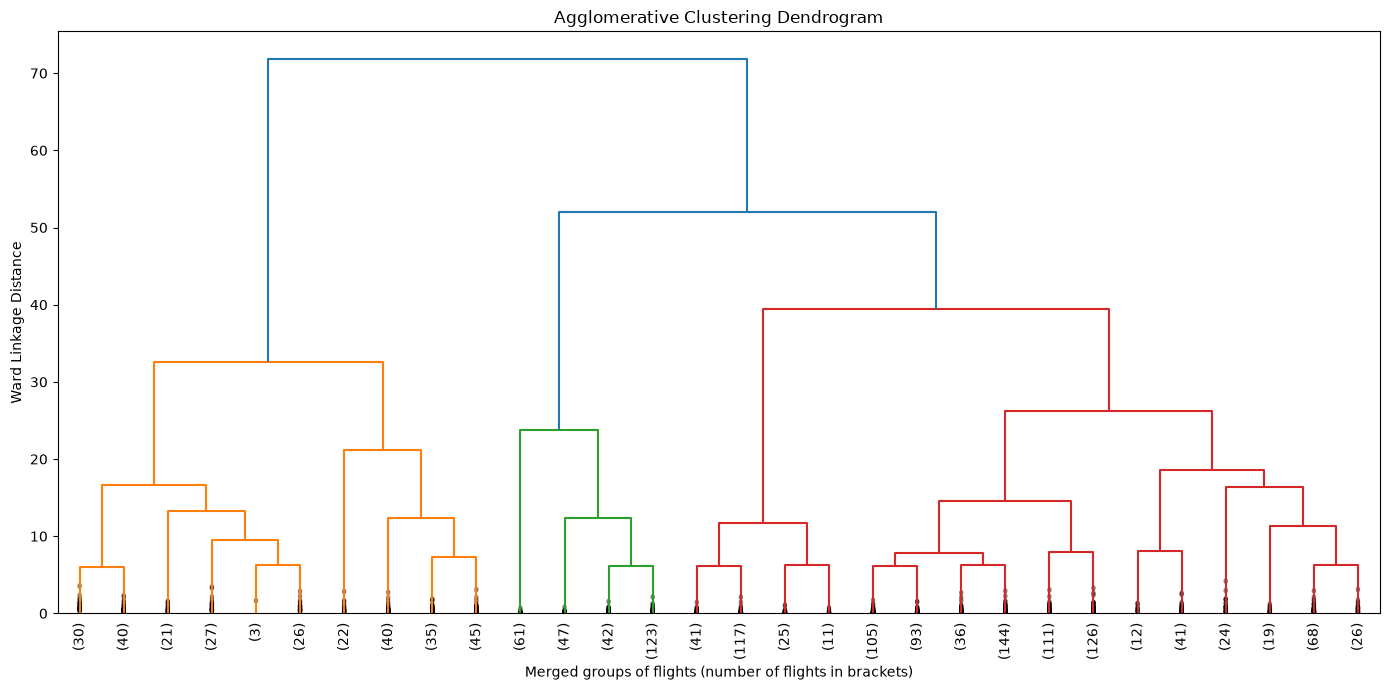

In [44]:
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

Z = linkage(X_scaled, method='ward')

plt.figure(figsize=(14, 7))

# there are over 1500 flights, so we only show the last 30 merged groups
dendrogram(
    Z,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90,
    show_contracted=True
)

plt.title('Agglomerative Clustering Dendrogram')
plt.xlabel('Merged groups of flights (number of flights in brackets)')
plt.ylabel('Ward Linkage Distance')

plt.tight_layout()
plt.show()

Conventional metrics for clustering, silhouette score and ARI.

Silhouette score is more sensible here since it measures how well the cluster describes the original categories. Naturally you wish this to be as close to 1.0 as possible.

ARI is not very useful here, since it literally compares how similar the clustering is to original categories. And since we combined categories into fewer clusters, ARI is going to be usually just 0.0 or close to it.

In [ ]:
from sklearn.metrics import silhouette_score, adjusted_rand_score

# if you can get both these metrics either 1 or very close to 1
# is means the clustering describes the original structure extremely well
# and you can replace the original high cardinality column with the cluster values instead

# Silhouette Score
sil_score = silhouette_score(
    X_scaled,
    flight_aggregates['Cluster']
)

# ARI
ari_score = adjusted_rand_score(
    flight_aggregates['flight'],
    flight_aggregates['Cluster']
)

print(f"Silhouette Score: {sil_score:.4f}")

# ARI doesn't help here since we are trying to measure a different thing here
# replacement for the original category
print(f"Adjusted Rand Index: {ari_score:.4f}")

Silhouette Score: 0.4745
Adjusted Rand Index: 0.0000


Finally, map the cluster value back to original DataFrame!

In [ ]:
flight_mapping = flight_aggregates[
    ['flight', 'Cluster']
].copy()

In [ ]:
df = df.merge(
    flight_mapping,
    on='flight',
    how='left'
)

After this, you can technically remove the original flight code, if you're happy with the clustering result!

In [ ]:
# note => the new cluster is a nominal category!
df

,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price,Cluster
0,SpiceJet,SG-8709,Delhi,Evening,0,Night,Mumbai,1,2.17,1,5953,4
1,SpiceJet,SG-8157,Delhi,Early_Morning,0,Morning,Mumbai,1,2.33,1,5953,4
2,AirAsia,I5-764,Delhi,Early_Morning,0,Early_Morning,Mumbai,1,2.17,1,5956,10
3,Vistara,UK-995,Delhi,Morning,0,Afternoon,Mumbai,1,2.25,1,5955,6
4,Vistara,UK-963,Delhi,Morning,0,Morning,Mumbai,1,2.33,1,5955,6
...,...,...,...,...,...,...,...,...,...,...,...,...
300148,Vistara,UK-822,Chennai,Morning,1,Evening,Hyderabad,0,10.08,49,69265,1
300149,Vistara,UK-826,Chennai,Afternoon,1,Night,Hyderabad,0,10.42,49,77105,1
300150,Vistara,UK-832,Chennai,Early_Morning,1,Night,Hyderabad,0,13.83,49,79099,1
300151,Vistara,UK-828,Chennai,Early_Morning,1,Evening,Hyderabad,0,10.00,49,81585,1


In [ ]:
# it's all about a compromise => average clustering result vs too many one hot encoded variables
# too many one hot encoded variables bring usually noise to the dataset

# this is one of the big dilemmas in ML engineering => how to handle categoricals
# should everything be a separate variable? (huge amounts of potential noise)
# technically the noise here is a form of variance and sparsity of values

# or should we use agglomerative clustering (one variable, but lost 
# accuracy regarding category relationships)

# NOTE: some tree-based models like Random Forest or XGBoost can handle
# nominal categories even if they are converted with a LabelEncoder (just
# random integer for each categories), since they still treat them as separate
# categories

# however, when having too many values, the tree based models can struggle
# with many options, since they have to make more and more splits between
# categories while creating the decision trees